Roots

By Pablo Angulo, Fabricio Macià and Daniel Sánchez-Mendoza for ETSIN@UPM

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import bisect, newton, minimize_scalar

# Root approximation, fixed points and optimization of functions of one variable

We are going to practice various techniques to find zeros (roots) of nonlinear functions of a real variable.

We start with a simple example:
$$
f(x) = x + \frac{1}{2}\sin(x) -1.
$$

Let's plot the function whose roots we want to find.

In [18]:
#Hallar ecuaciones de una variable, maximizar o minimizar una función, necesitaremos la derivada
#Lo que hacemos es ir reduciendo el intervalo en el que hay una raíz

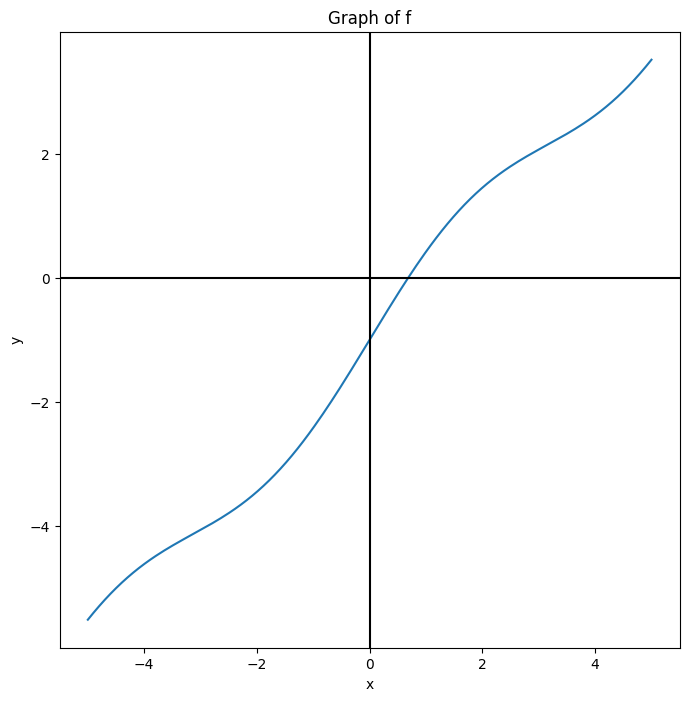

In [17]:
def f(x):
    return x + np.sin(x) / 2 - 1


xmin = -5
xmax = 5
xs = np.linspace(xmin, xmax, 200)
ys = f(xs)
plt.figure(figsize=(8, 8))
plt.plot(xs, ys)
plt.title("Graph of f")
plt.xlabel("x")
plt.ylabel("y")
plt.axhline(color="k")
plt.axvline(color="k")
plt.show()

The graph of the function can give us clues about the number and approximate location of its roots, but we need to demonstrate the existence and uniqueness with one of these techniques:

 - If the function is continuous, and in an interval it changes sign, there must be a root in that interval (_Bolzano's theorem_).
 - If in an interval the derivative does not change sign, there cannot be more than one root (consequence of _Rolle's theorem_).

In our example, $f$ changes sign in the interval $(-1,1)$, hence there is a root in this interval:

In [12]:
f(-1), f(1)

(-2.4207354924039484, 0.42073549240394836)

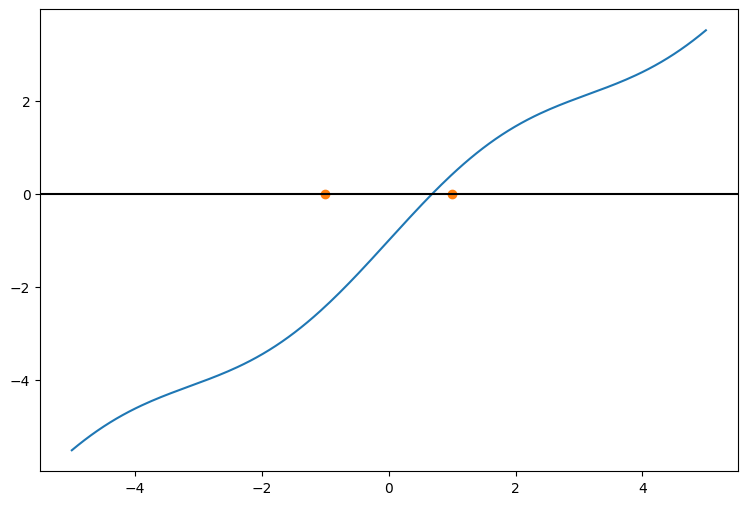

In [13]:
plt.figure(figsize=(9, 6))
plt.plot(xs, ys)
xleft = -1
xright = 1

plt.plot([xleft, xright], [0, 0], "o")
plt.axhline(color="k")
plt.show()

The derivative of $f$ is easy to calculate:
$$
f'(x) = 1 + \frac{1}{2}\cos(x)
$$
and we can easily bound it from below if we write
$$
1 = f'(x) - \frac{1}{2}\cos(x),
$$
and use the triangular inequality
$$
1 \leq |f'(x)| + \frac{1}{2}|\cos(x)|,
$$
to obtain
$$
|f'(x)| \geq 1 - \frac{1}{2}|\cos(x)| \geq 1 - \frac{1}{2} = \frac{1}{2} > 0.
$$
That is, $f'$ is always positive, therefore $f$ is increasing in all $\mathbb{R}$, and $f$ has only one root.

Finding this root analytically is not possible, so we must approximate it.

## Bisection method

 - OBJECTIVE: Find an interval [x1, x2] such that there is a root x* of f in that interval.
 - START: We start from an interval `[xleft, xright]` where $f$ changes sign.
 - REPEAT: Evaluate $f$ at `xmed = (xleft + xright)/2`. We are left with a new interval where there is a change in sign and length half that of the previous one.
 - UNTIL: We finish when the obtained interval has a length less than `xtol`.

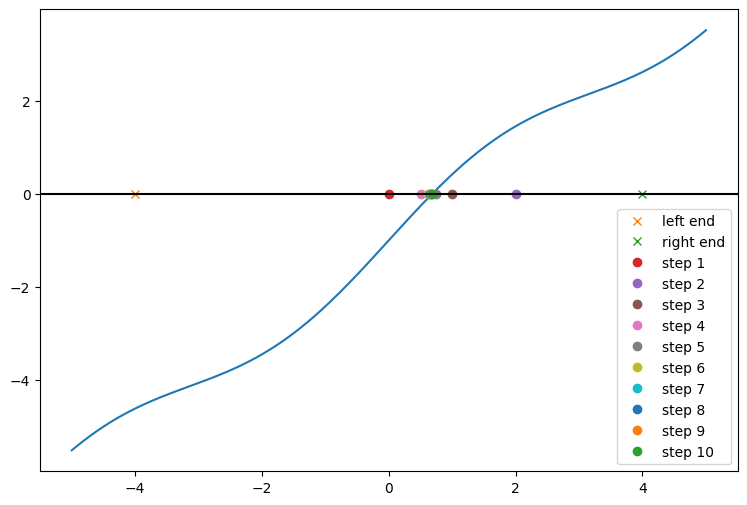

In [19]:
plt.figure(figsize=(9, 6))
plt.plot(xs, ys)

xleft = -4
xright = 4
xtol = 1e-2
plt.plot([xleft], [0], "x", label="left end")
plt.plot([xright], [0], "x", label="right end")


j = 1
sleft = np.sign(f(xleft))
sright = np.sign(f(xright))
while xright - xleft > xtol:
    xmed = (xleft + xright) / 2
    smed = np.sign(f(xmed))
    if smed == sleft:
        xleft = xmed
    else:
        xright = xmed
    plt.plot([xmed], [0], "o", label="step %d" % j)
    j = j + 1

plt.legend()
plt.axhline(color="k")
plt.show()

## Error in the bisection method

Remember that in each step of the bisection method we obtain a new value $x_n$ (the midpoint of the interval that is subdivided), which becomes one of the ends of the new interval that will be subdivided in the next step. 

For example, in the first iteration 

$$
x_1=\frac{a+b}{2}.
$$

The error at iteration $n$ is: 

$$
e_n=x_n-x_*,\quad \text{ where } f(x_*)=0.
$$

We know, from how the iterations have been built, that:

$$
|e_n|\leq \frac{b-a}{2^n}.
$$

In particular, this suggests that the error at stage $n+1$ and the error at stage $n$ are related by:

$$
|e_{n+1}| \approx \frac{1}{2}|e_n|.
$$

Advantages:
- It always converges.

Disadvantages:
- It can only be applied if around the roof the function changes sign (minor drawback).
- It usually converges more slowly than other methods (major drawback).

In [20]:
#Para una función que solo pasa por un punto del eje x no podemos usar este método

### Exercise 1:

Write the bisection method as a function with inputs

 - A continuous function `f`,
 - The ends of an interval `a` and `b`,
 - A tolerance for the `xtol` error,

and outputs

 - If `f(a)*f(b)>0`, it breaks and returns nothing (prints an error message, throws an "exception", etc),
 - If `f(a)*f(b)<=0`, returns a value that is at distance less than `xtol` from the root of `f`.

In [33]:
def bisection(f,a,b,xtol):
    #comprobar que f(a) y f(b) tienen signos opuestos
    #comenzar la iteración;
    #parar si x_n es una raíz o sabemos que el error es menor que xtol
    if np.sign(f(a))==np.sign(f(b)): 
        print ("error en el intervalo")
        return
    
    j=1
    sa=np.sign(f(a))
    sb=np.sign(f(b))
    
    while b-a > xtol:
        xmed=(a+b)/2
        smed=np.sign(f(xmed))
        if smed == sa:
            a =xmed
        else:
            b=xmed
        j=j+1
    return xmed

In [43]:
def f(x):
    return x**3-4*x+np.log(1+x**2)
bisection  (f,0,1,1e-6)

9.5367431640625e-07

### Exercise 2:

Find the the roots of 

$$
f(x) = x^3 - 4x + \log(1+x^2).
$$

Attention: is there more than one root? how many are positive?

In [44]:
def f(x):
    return x**3-4*x+np.log(1+x**2)


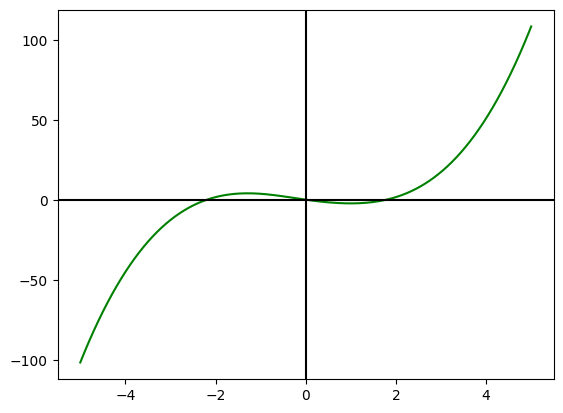

In [47]:
xs=np.linspace(-5,5,200)
ys=f(xs)
plt.plot(xs,ys,"g")
plt.axhline(color="k")
plt.axvline(color="k")

In [49]:
bisection  (f,1,4,1e-10)

1.7882339326606598

In [50]:
bisection  (f,-3,-1,1e-6)

-2.1914243698120117

### Exercise 3:

Write the bisection method as a function with inputs

 - A continuous function `f`,
 - The ends of an interval `a` and `b`,
 - A tolerance for the `xtol` error,

and outputs

 - If `f(a)*f(b)>0`, it breaks and returns nothing (prints an error message, throws an "exception", etc),
 - If `f(a)*f(b)<=0`, returns a value that is at distance less than `xtol` from the root of `f` and an array with the error bounds at each iteration.

### Exercise 4:

Using the function that you built in the previous exercise to:

$$
f(x) = x + \frac{1}{2}\sin(x) -1,\quad a=-4,\quad b=4.
$$

Plot the error $e_n$ committed in each iteration, and in a different plot, the quotient $e_{n+1}/e_n$.

In [ ]:
def h(x):
    return x+1/2*np.sin(x)

In [53]:
bisection  (h,-4,4,1e-10)

0.6840366566902958

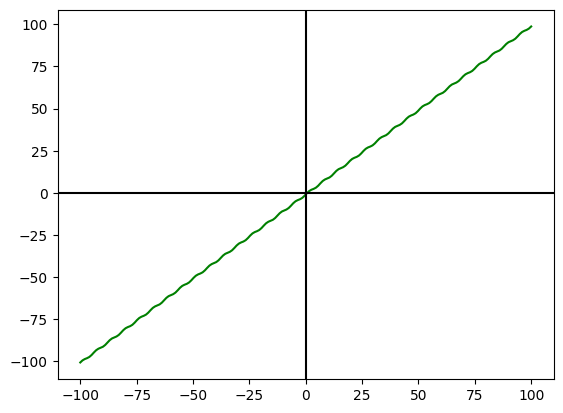

In [57]:
xs=np.linspace(-100,100,200)
ys=h(xs)
plt.plot(xs,ys,"g")
plt.axhline(color="k")
plt.axvline(color="k")

### Exercise 5:

 - Look for a function from the `scipy.optimize` library that implements the bisection algorithm, compare its arguments, the way of reporting the result and its behavior in case of incorrect arguments with the your own implementation above.
 - Compare the result of this function with yours in one of the previous examples.

## Secant method

The secant method, like the bisection method, starts by choosing two points $x_0,x_1$ that we think are good approximations of the root $x_*$ of the equation

$$
f(x)=0
$$

that we want to find. But, unlike the bisection method, the root does not have to be in the interval $[x_0,x_1]$.

The algorithm produces a sequence of approximations $x_2,x_3,\dots,x_n$ to the root as follows:

We choose as $x_2$ the root of the line that passes through $(x_0, f(x_0))$ and $(x_1,f(x_1))$. In other words, we replace $f$ by its *linear interpolation* for the nodes $x_0$ and $x_1$. This line has the equation:

$$
y = \left(\frac{f(x_1) - f(x_0)}{x_1-x_0}\right) (x - x_1) + f(x_1).
$$

Its root is the value of $x$ that satisfies

$$
y=0=\left(\frac{f(x_1) - f(x_0)}{x_1-x_0}\right) (x - x_1) + f(x_1),
$$

therefore

$$
x_2:= x_1 - \frac{f(x_1)}{f(x_1)-f(x_0)}(x_1-x_0).
$$

In general, for $n\geq$ we calculate $x_n$ from $x_{n-1}$ and $x_{n-2}$ as

$$
x_n:= x_{n-1} - \frac{f(x_{n-1})}{f(x_{n-1})-f(x_{n-2})}(x_{n-1 }-x_{n-2}).
$$

Advantages:
 - When it converges, it does so faster than the secant method.
 
Disadvantages:
 - It does not always converge.

### Exercise 6:

Write a function that implements the secant method:
 - What arguments do you need?
 - What stopping criterion are you going to choose? 

In [64]:
def secante (f, x0, x1, xtol=1e-6):
    Nmax = 100
    if f(x0)== f(x1):
        print ("No se puede comenzar la iteración porque f(x0)=f(x1)")
        return
    
    j=1
    while np.abs(x1-x0)>xtol and j<=Nmax:
        xn=x1-f(x1)/(f(x1)-f(x0))*(x1-x0)
        x0=x1
        x1=xn
        j=j+1
    return xn

In [65]:
secante(h,-4,4,1e-10)

0.6840366566778294

## *Regula falsi* or false position method

- It is a combination of the bisection and secant method. 
- It is identical to the bisection method; but instead of choosing the midpoint of the interval, we choose the root of the line secant to the graph of the function through the ends of the interval.

This method is not commonly used, but this philosophy gives rise to **hybrid methods** that are used in practice, such as the **Brent method**.

## Fixed point method

This method consists of writing the equation

$$
f(x)=0,
$$

in the form

$$
x=g(x).
$$

A point that verifies the previous equation is a **fixed point** of the function $g$.

Not all functions have fixed points, but there are two cases where we can guarantee that this is the case:

- If $g:[a,b]\rightarrow [a,b]$ (the function $g$ sends any point in the interval $[a,b]$ to another point in the *same* interval $[a,b] $) is a continuous function, then $g$ has a fixed point in the interval $[a,b]$.
- If $g:[a,b]\rightarrow [a,b]$ continuous and its derivative satisfies
$$
|g'(x)|\leq k < 1, \quad\text{for any } x \text{ in } (a,b), 
$$ 
then there is a single fixed point in the interval $[a,b]$.

In the example above, the equation

$$
f(x) = x + \frac{1}{2}\sin(x) -1=0,
$$

can be written as

$$
x=1-\frac{1}{2}\sin(x), 
$$

which has the structure of fixed point equation with 

$$
g(x)= 1-\frac{1}{2} \sin(x).
$$

The fixed point method consists of:

 - start with a (rough) approximation $x_0$ of the fixed point, either chosen at random, or constructed by other methods (bisection, for example),
 - construct successive approximations of the form
$$
x_{n+1}=g(x_n),
$$
 - until the difference between $x_n$ and $x_{n+1}$ is smaller than our tolerance.

If $g'(x)$ is small near the fixed point (this means that $g(x)$ has no abrupt variations near the fixed point), then the approximations $x_n$ get closer to the fixed point as $n$ grows.

More precisely: 
If
- $x_*=g(x_*)$,
- $|g'(x)|\leq k < 1$ for $x$ within an interval $(x_*-\delta,x_*+\delta)$, 
- the first approximation $x_0$ is located in $(x_*-\delta,x_*+\delta)$,

then the error $e_n=x_n-x_*$ tends to zero as $n\to\infty$.

## Error in the fixed point method

Notice that

$$
|e_n|=|x_n-x_*|=|g(x_{n-1})-g(x_*)|=\underbrace{|g'(\zeta_n)|}_{\zeta_n\text{ between } x_{n-1}\text{ y }x_*}|x_{n-1}-x_*|=\underbrace{|g'(\zeta_n)|}_{\zeta_n\text{ between } x_{n-1}\text{ y }x_*}|e_{n-1}|\leq k|e_{n-1}|,
$$

from which follows that (whenever the method converges)

$$
\lim_{n\to\infty}|\frac{|e_{n+1}|}{|e_n|}= |g'(x_*)|,\quad \text{ and } \quad e_n\leq k^n |e_0|. 
$$

Similarly we have

$$
|x_{n+1}-x_n|=|g(x_n)-g(x_{n-1})|=\underbrace{|g'(\zeta_n)|}_{\zeta_n\text{ between }x_n \text{ y }x_{n-1}}|x_{n}-x_{n-1}|.
$$

Applying this $n$ times we obtain

$$
|x_{n+1}-x_n|=|g(x_n)-g(x_{n-1})|\leq k|x_{n}-x_{n-1}|\leq\dots\leq k ^n |x_1-x_0|,
$$

from which follows, with a little more effort, that 
$$
|e_n|< \frac{k^n}{1-k}|x_1-x_0|.
$$

### Quadratic convergence

What happens when $|g'(x_*)|=0$?

In this case, the speed of convergence is higher. To see why, we proceed as before; but this time we do a Taylor expansion of $g(x)$ in $x=x_*$ up to order two:

$$
e_{n+1} = x_{n+1}-x_*=g(x_n) - g(x_*) = g'(x_*)(x_n - x_*)+ \underbrace{\frac{g'' (\zeta_n)}{2}}_{\zeta_n\text{ between }x_n \text{ and }x_{*}}(x_n-x_*)^2.
$$

Since $g'(x_*)=0$, we have that that

$$
e_{n+1} = \frac{g''(\zeta_n)}{2}(e_n)^2.
$$

Therefore, if $e_n$ converges to zero, it holds that

$$
\frac{e_{n+1}}{(e_n)^2}\to \frac{|g''(x_*)|}{2},\quad \text{ when } n\to\infty.
$$

In other words, $e_n$ goes to zero quadratically:

$$
|e_{n+1}|\approx \frac{|g''(x_*)|}{2} |e_n|^2.
$$


Advantages:
- It is easy to implement.

Disadvantages:
- There is no guarantee that the choice we make of $x_0$ will result in a sequence of approximations of the fixed point $x_*$. Even when $|g'(x)|<1$ in a neighborhood of $x_*$ one has to make sure that $x_0$ is close enough to $x_*$.
- If $|g'(x_*)|>1$ the approximations **do not converge**.

### Exercise 7:

Write a function that implements fixed point method with inputs:

 - A continuous `g` function,
 - An initial approximation `x_O`,
 - A maximum number of iterations `N`,
 - A tolerance for  error `tol` (optional parameter, default `1.e-6`)

and output:

 - If the maximum umber of iterations `N` is reached, or the absolute value of `x-g(x)` is less than `tol`, return the last iteration.


In [73]:
def puntofijo (g, x0, xtol=1e-6):
    Nmax = 100
    j=1
    while np.abs(g(x0)-x0)>xtol and j<=Nmax:
        x0=g(x0)
        j=j+1
    return x0

In [77]:
puntofijo (h,0)

-87.5907698382811

### Exercise 8:

Let $f(x) = x - e^{-x}$, we are going to solve $f(x) = 0$

- Writing it as the fixed point equation $x = e^{-x}$ ($x = g(x)$ with $g(x) = e^{-x}$).
- Writing it as the fixed point equation $x = -\ln x$.

Check that both formulations are equivalent.

Use the fixed point method for each of the formulations, using several initial approximations. Could you explain what happens?

## Newton's method

Again, we are going to solve an equation of the form

$$
f(x)=0.
$$

If we take an approximation $x_n$, it is unlikely that $f(x_n)=0$.  However, one can expect there to be a $\delta_n$ correction such that $x_{n+1} = x_n + \delta_n$ satisfies
$$
    f(x_{n+1}) = 0. 
$$

Let's do a Taylor expansion around $x_n$: 

$$
    f(x_n + \delta_n) = f(x_n) + f'(x_n) \delta_n + O(\delta_n^2).
$$

If we substitute this expression into $f(x_{n+1})=0$ and neglect the quadratic terms in $\delta_n$ we arrive at:

$$
    f(x_n) + f'(x_n) \delta_n =0.
$$

Solving, we obtain:

$$
\delta_n=-\frac{f(x_n)}{f'(x_n)}.
$$

Therefore,

$$
x_{n+1} = x_n -\frac{f(x_n)}{f'(x_n)}.
$$

## Error in Newton's method

Newton's method can be interpreted as a fixed point iteration
$$
x=g(x)
$$
associated with the function
$$
g(x)=x - \frac{f(x)}{f'(x)}.
$$
An immediate calculation shows that, as long as $f'(x)\neq 0$ and the second derivative $f''(x)$ exists, we have
$$
g'(x)=\frac{f(x)f''(x)}{(f'(x))^2}.
$$

So, if $f(x_*)=0$ then $g'(x_*)=0$, which means that we have **quadratic convergence**:
$$
\frac{e_{n+1}}{(e_n)^2}\to \frac{|g''(x_*)|}{2},\quad \text{ when } n\to\infty.
$$

This method converges (when it does converge) much faster than the bisection method or the general fixed point method which have **linear convergence**.

However, we cannot know a priori whether the method converges or not. To do this, the initial iteration $x_0$ must be close enough to the exact root $x_*$, and the condition
$$
|g'(x)|=\left|\frac{f(x)f''(x)}{(f'(x))^2}\right|<1,
$$
must hold in the interval whose ends are $x_0$ and $x_*$. This is difficult to verify in practice.

## Implementation of Newton's method

Since we have no guarantee of convergence, we must code our method defensively. If we write, for example:
```python
def newton_method(f, fp, x0, ytol):
    x = x0
    error = np.abs(f(x))
    while error > ytol:
        x = x - f(x)/fp(x)
        error = np.abs(f(x))
    return x
```
we will find ourselves in an infinite loop when the method does not converge.

One way to avoid this problem is to impose a maximum number of iterations using a counter:
```python
def newton_method(f, fp, x0, ytol, maxiter=100):
    x = x0
    error = np.abs(f(x))
    k = 0 #counter
    # the loop stops when the desired precision is achieved,
    # or if maximum iterations are reached
    while error > ytol and k<maxiter:
        x = x - f(x)/fp(x)
        error = np.abs(f(x))
        k = k + 1
    return x
```

In the previous definition we have used the __stopping criterion__ $|f(x_n)|<\mathrm{ytol}$.

The other common stopping criterion is $|x_{n+1}-x_n|<\mathrm{xtol}$.

The code that corresponds to this other stopping criterion is:

```python
def newton_method(f, fp, x0, xtol, maxiter=100):
    x = x0
    #We start with an infinite error, simply so that
    #the program does not stop before starting
    error = np.inf
    k = 0 #counter
    # the loop stops when the desired precision is achieved,
    # or if maximum iterations are reached
    while error > xtol and k<maxiter:
        xnew = x - f(x)/fp(x)
        error = np.abs(xnew - x)
        x = xnew
        k = k + 1
    return x
```

Finally, since there are no guarantees of success, it is usefull to return not only our estimate of the root, but also our estimate of the error obtained:

```python
def newton_method(f, fp, x0, xtol, maxiter=100):
    x = x0
    #We start with an infinite error, simply so that
    #the program does not stop before starting
    error = np.inf
    k = 0 #counter
    # the loop stops when the desired precision is achieved,
    # or if maximum iterations are reached
    while error > xtol and k<maxiter:
        xnew = x - f(x)/fp(x)
        error = np.abs(xnew - x)
        x = xnew
        k = k + 1
    return x, error
```

In [ ]:
def newton_method(f, fp, x0, xtol, maxiter=100):
    x = x0
    # We start with an infinite error, simply so that
    # the program does not stop before starting
    error = np.inf
    k = 0  # counter
    # the loop stops when the desired precision is achieved,
    # or if maximum iterations are reached
    while error > xtol and k < maxiter:
        xnew = x - f(x) / fp(x)
        error = np.abs(xnew - x)
        x = xnew
        k = k + 1
    return x, error

In [ ]:
f = lambda x: x**2 - 2
fp = lambda x: 2 * x

# 2 iterations are not sufficient to achieve the desired precision
print(newton_method(f, fp, 1, 1e-8, 2))
# 10 iterations are sufficient to achieve the desired precision
# The error estimate is better than the minimum tolerance we asked for
print(newton_method(f, fp, 1, 1e-8, 10))
print(newton_method(f, fp, 1, 1e-8, 100))

### Calculate derivatives using symbolic calculus

For Newton's method, and for many others, it is necessary to be able to evaluate the derivative of a function. Our options are:
 - We can calculate the derivative by hand, although:
     + it is easy to make a mistake if the calculation is long.
     + cannot be automated: when changing the function you have to differentiate again.
 - We can use numerical derivation, as we have seen before.
 - We can use symbolic calculus, which always manages to calculate the derivative of a function.
 - We can look for another method that does not need the calculation of the derivative. 
 
Among the methods we have seen: which method is most similar to Newton's method and does not require the calculation of the derivative?

### Exercise 9:

 - Write the documentation (_'docstring'_) for the `newton_method` function.
 - Compare Newton's method with that of bisection in the previous examples. Note the importance of a good first approach. Compare the number of iterations necessary to achieve the same precision with both methods.

### Exercise 10:

Now apply Newton's method to solve the equation:

$$
    f(x) = x^2 + x - \sin(x)=0.
$$

Take $x_0=0.9$ as an initial approximation. Compare the rate at which the error tends to zero for this example and the previous examples. Do you notice any difference? Can you explain it?

## Summary: Newton`s and Secant methods on one variable

 - **Newton**'s method searches for roots of f(x), iterating 
    $$x_{n+1}=x_{n} - \frac{f(x_n)}{f'(x_{n})}$$
    - It is a fixed point iteration, with $g(x) = x - f(x)/f'(x)$.
    - It is not easy to know if it will converge... but when it does it is of order 2.
    - We must evaluate the derivative.
 - The **secant** method is similar to Newton's, except that the derivative $f'(x)$ is replaced by the incremental quotient:
   $$f'(x_n)\approx \frac{f(x_{n})-f(x_{n-1})}{x_{n}-x_{n-1}}.$$
   The resulting method is: 
   $$x_{n+1}=x_{n} - \frac{f(x_n)\left(x_{n}-x_{n-1}\right)}{f(x_{n})-f( x_{n-1})}.$$
    - There is no need to evaluate the derivative.
    - The order of convergence is somewhat lower (research on the internet what the order is).

The Newton's and Secant methods have qualitative differences with the bisection method:
 - We do not have an interval that limits the root, but rather a point that approximates it.
 - We do not have a theoretical bound on the error between the points $x_n$ and the root, unless the convergence conditions are verified and we can bound the second derivative. We have two options:
     + evaluate the error in the $y$: the difference between $f(x)$ and $0$.
     + estimate the error in $x$ by comparing $x_n$ with $x_{n+1}$.
 - If we fail to verify the hypotheses of the convergence theorems (in particular the boundedness $f''$), we have no guarantee of success.

### Exercise 11:

 - Look for the official newton and secant methods in `scipy.optimize`. Compare the decisions made and try both methods in a specific example.
 - Compare the secant method with Newton's method to calculate square roots. Compare the number of iterations necessary to achieve the same precision with both methods.

### Exercise 12:

Could you numerically estimate the order of convergence of the secant method? That is, find (through numerical experiments) what number $\gamma>0$ that satisfies 
$$
 \frac{|e_{n+1}|}{|e_n|^\gamma}\to m>0,\quad \text{when }n\to\infty,
$$
whenever the method converges.

To do this, transform the problem by taking the logarithm and use a least squares fit.
   * That is, look for values ​​$\gamma, m$ such that 
      $$\sum_n \left(\log\left(\frac{|e_{n+1}|}{|e_n|^\gamma}\right) - \log(m)\right)^2$$
     is as small as possible.
   * Use `gamma, logm = np.polyfit(en_0, en_1)` to find the coefficients of the least squares fit, where `en_0` is the array with the values ​​$\log(|e_n|)$, and `en_1` is the array with the values ​​$\log(|e_{n+1}|)$, so that the least squares line is 
   $$\log(|e_{n+1}|) = \gamma\cdot \log( |e_{n}|) + \log(m).$$
   *  What is an approximate value for $\gamma$?

## Hybrid methods

By combining methods like the previous ones, practical methods like **Brent's** are obtained.

### Exercise 13:

Read the [official scipy documentation](https://docs.scipy.org/doc/scipy/reference/generated/scipy.optimize.minimize_scalar.html#scipy.optimize.minimize_scalar) on optimizing scalar functions. Find the default method.

## Roots and fixed points in several variables

 - If $f(a)$ and $f(b)$ have opposite signs, then $f$ has a root in the interval $[a,b]$.

   This statement has a theoretical equivalent in several variables, but has no general practical application.

 - If $g:[a,b]\rightarrow [a,b]$ is continuous, then $g$ has a fixed point in the interval $[a,b]$.

   In several variables, this is know as **Brouwer fixed point theorem**:

   Every continuous function $g:\mathbf{B}\rightarrow\mathbf{B}$, where $\mathbf{B}\subset\mathbb{R}^n$ is a bounded, closed and convex set, has at least one fixed point.

 - If $g:[a,b]\rightarrow [a,b]$ is continuous and $|g'(x)|\leq k < 1$ then
    * $g$ has a single fixed point $x^*$ in $[a,b]$.
    * $x_{n+1}=g(x_n)$ converges to $x^*$, *for any initial point* $x_0$.
    * $|x_n - x^*| < \frac{k^n}{1-k}|x_1-x_0|$.

    This result holds in several variables almost without change:

   If $g:\mathbf{B}\rightarrow \mathbf{B}$ is continuous and $\Vert D g(x)\Vert\leq k < 1$ then
     * $g$ has a single fixed point $x^*$ in $\mathbf{B}$.
     * the sequence $x_{n+1}=g(x_n)$ converges to $x^*$, *for any initial point* $x_0$.
     * $|x_n - x^*| < \frac{k^n}{1-k}|x_1-x_0|$.  

If $g:\mathbb{R}^n\rightarrow\mathbb{R}^n$, we have, by the fundamental theorem of calculus, for $y=x+h$:

$$ g(y)-g(x)=\left(\int _{0}^{1}Dg(x+th)\cdot h\,dt\right)$$

then if $\Vert D g(x) \Vert \leq k$ for all $x$, we have that

$$
\begin{split}
\Vert g(y) - g(x)\Vert
&=\left\Vert\int _{0}^{1}Dg(x+th)\cdot h\,dt\right\Vert\\
&\leq \int _{0}^{1} \Vert Dg(x+th)\cdot h\Vert\,dt\\
&\leq k\int _{0}^{1} \Vert h\Vert\,dt
\leq k \Vert y-x\Vert 
\end{split}
$$

Therefore, if $\Vert D g(x)\Vert\leq k < 1$ then *applying $g$ reduces distances*.

**Note**: We haven't yet discussed *matrix norms*, $\Vert D g(x) \Vert$, but we'll see later that for a suitable norm, 
$$\Vert D g(x) \Vert \leq k\Rightarrow \Vert D g(x)\cdot v \Vert \leq k\Vert v\Vert.$$

A map such that $\Vert g(y)-g(x)\Vert \leq k\Vert y- x\Vert$, for $k<1$, is called **contractive**. Under a contractive map the image of a set reduces until it converges to a point.

![](ContractiveMap.gif)

We define the sequence $x_{n+1} = g(x_n)$, starting with any point $x_0$. Then

$$\Vert x_{n+1} - x_n\Vert = \Vert g(x_n) - g(x_{n-1})\Vert \leq k \Vert x_n-x_{n-1}\Vert,$$

and in the same way as in a one variable case

$$\Vert x_n - x^*\Vert < k^n\Vert x_0-x^\ast\Vert, \qquad \Vert x_n - x^*\Vert < \frac{k^n}{1-k}\Vert x_1-x_0\Vert.$$

## Relationship between  roots and minimization

The problems of finding roots and minimizing (or maximizing) functions are similar:
$$f:\mathbb{R}^n\rightarrow\mathbb{R}^n$$
$$h:\mathbb{R}^n\rightarrow\mathbb{R}$$

- The minima of $h$ are **critical points** $\Rightarrow$ are __roots__ of the system $\nabla h = \mathbf{0}$.
- If $h$ is **convex**, the unique minimum of $h$ is the unique root of $\nabla h = \mathbf{0}$.
- The function $f$ can have **many roots**; the function $h:\mathbb{R}^n\rightarrow\mathbb{R}$ can have **many local minima and maxima**.
- $f(\mathbf{x_0})=\mathbf{0}$ $\Rightarrow$ The function $x\rightarrow\Vert f(\mathbf{x})\Vert^2$ reaches an absolute minimum at $\mathbf{x_0}$.
- There is a *direct analogue to the bisection method* for minimizing functions of **one** variable: [Golden-ratio search](https://en.wikipedia.org/wiki/Golden-section_search).

However, there is an important *difference*:

- **All roots of a function are equivalent** a priori: one is enough, or we want them all.
- When we search for the minimum of a function, we are primarily interested in the **absolute minimum**. A point $x$ with a small value of $h$ is often preferable to a local minimum with a larger value of $h$.

### Weierstrass's Theorem

*A continuous function always reaches a maximum and a minimum on a "closed" and bounded set.*

Also known as the [Extreme Value Theorem](https://en.wikipedia.org/wiki/Extreme_value_theorem).

Problems:
- A function defined on an unbounded set may have neither a maximum nor a minimum.
- The maximum or minimum may be in the interior or on the boundary of the set.
- A function may have many local maxima and minima.

### Local and absolute minima

If a function has many local minima, a minimum-finding algorithm may get stuck at a local minimum and fail to reach the absolute minimum.

In [ ]:
def f(x):
    return (x - 2) * x * (x + 2) * (x + 3)


xs = np.linspace(-3.5, 2.5, 100)
ys = f(xs)
result_1 = minimize_scalar(f, bounds=(-3, 0), method="bounded")
result_2 = minimize_scalar(f, bounds=(0, 2), method="bounded")
minima = np.array([result_1.x, result_2.x])

plt.figure(figsize=(9, 6))
plt.plot(xs, ys)
plt.plot(minima, f(minima), "og")
plt.show()

In [ ]:
# Using the Bounded method, we find a local minimum with specified bounds as:
result = minimize_scalar(f, bounds=(-3, -1), method="bounded")
result

In [ ]:
minimize_scalar(f)

In the previous example, a call to `minimize_scalar` with no arguments returned the absolute minimum, but this doesn't have to be the case:

In [ ]:
def f(x):
    return (x - 2) * x * (x + 2) * (x + 3) * (1 + (x - 1) ** 2)


result_1 = minimize_scalar(f)
print(result_1.x, result_1.fun)

result_2 = minimize_scalar(f, bounds=(-3, -1), method="bounded")
print(result_2.x, result_2.fun)

In [ ]:
xs = np.linspace(-3.5, 2.5, 100)
ys = f(xs)

plt.figure(figsize=(9, 5))
plt.plot(xs, ys)
plt.plot([result_1.x, result_2.x], [result_1.fun, result_2.fun], "go")
plt.show()

## Newton's method in several variables

**Newton's** method finds roots of $f(x)$, iterating
$$x_{n+1}=x_{n} - \frac{f(x_n)}{f'(x_{n})}.$$

**Newton's** method in several variables uses the iteration
$$x_{n+1}=x_{n} - \left(\nabla f(x_n)\right)^{-1}f(x_n).$$

- It is a fixed-point iteration, with $g(x) = x - \left(\nabla f(x_n)\right)^{-1}f(x)$.
- It's not easy to know if it will converge... but when it does, it's of order 2.
- You have to evaluate the Jacobian matrix, *but it's not necessary to invert it*, just solve the system $\left(\nabla f(x_n)\right)y_n = f(x_n)$.

## More numerical methods for finding roots

There are many methods to find roots of functions $f:\mathbb{R}^n\rightarrow\mathbb{R}^n$.

``scipy.optimize.root`` ([scipy.optimize](https://docs.scipy.org/doc/scipy/reference/optimize.html))

```
    method : str, optional
    Type of solver. Should be one of

            ‘hybr’ ‘lm’ ‘broyden1’ ‘broyden2’ ‘anderson’ ‘linearmixing’ ‘diagbroyden’ ‘excitingmixing’ ‘krylov’ ‘df-sane’
```
- None offer complete guarantees of finding the root.
- Some actually attempt to minimize $\Vert f(x)\Vert^2$.
- The **Broyden** type are similar to Newton's, but try to avoid calculating the gradient (in the spirit of the **secant** method).

## Optimization of functions of several variables

See [scipy.optimize](https://docs.scipy.org/doc/scipy/reference/optimize.html).

- We know that it is impossible to find the optimal value in a guaranteed manner, *except if $f$ is convex*.
- Optimization can end in a local minimum or maximum.

Some important ideas:

#### Gradient Descent and its variants:

To get closer to a minimum of $f$, move a little in the $-\nabla f(x)$ direction.

- The algorithms in this family take little time to reach a **local minimum**.
- The local minimum can have a value much larger than the absolute minimum.

#### Simulated annealing

The goal is to maximize the function.

- A high temperature accepts solutions lower than the "best value found so far".
- A low temperature **does not** accept solutions lower than the "best value found so far".
- It starts at a high temperature and progressively lowers it...

![](SimulatedAnnealing.gif)

#### Basin hopping

- A random jump.
- Then follows the gradient to a local minimum.
- Accepts or rejects the change based on *temperature*.

#### Genetic algorithms

Combines several biologically inspired ideas:

- Stores multiple $x_i$ points, instead of just one.
- Mutations.
- Recombinations.
- Natural selection.